In [20]:
import numpy as np
import pandas as pd

# Data Visualisation
import matplotlib.pyplot as plt 
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [21]:
advertising = pd.DataFrame(pd.read_csv("D:/projects/python_tum_dosyalar/data-science-lab/ae_makina_ogrenmesi/16_basit_dogrusal_regresyon/data/advertising.csv"))
advertising.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


(TV           0.901208
 Radio        0.349631
 Newspaper    0.157960
 Sales        1.000000
 Name: Sales, dtype: float64,
 <seaborn.axisgrid.PairGrid at 0x1c1326f9450>)

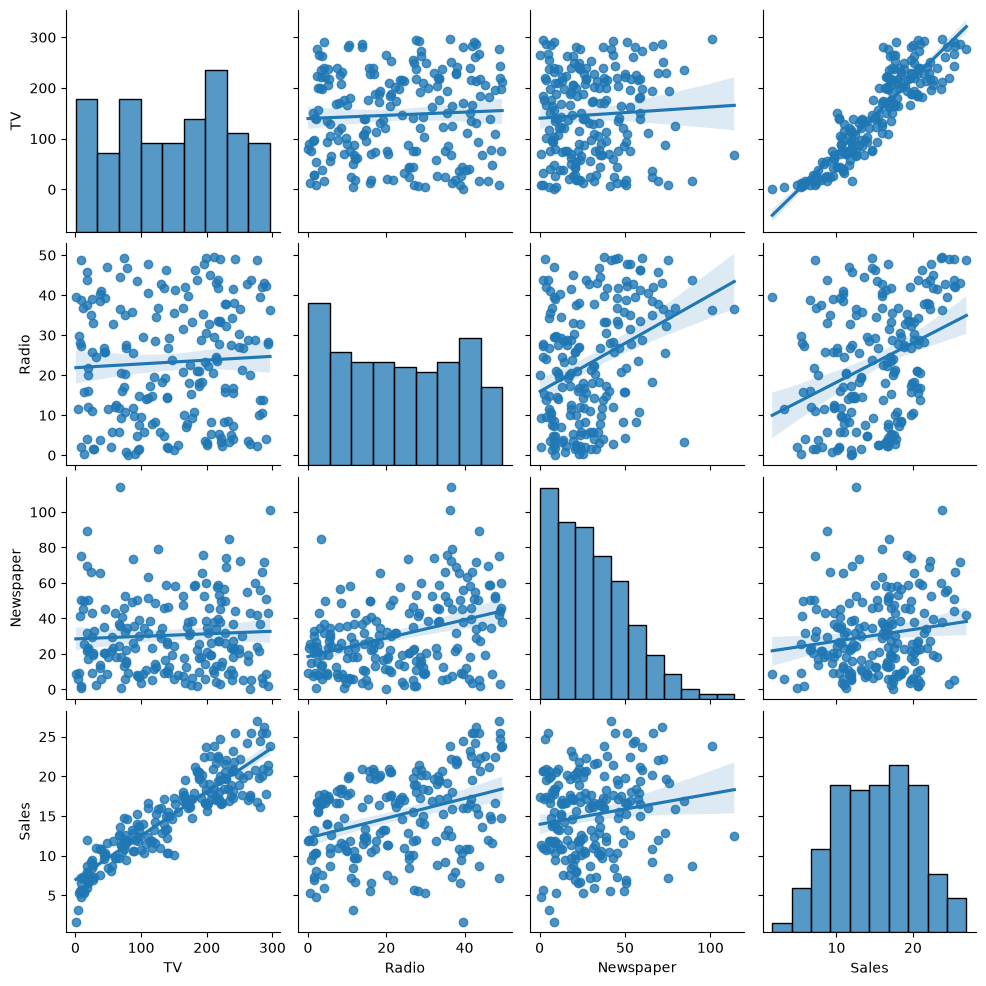

In [22]:
advertising.corr()["Sales"],sns.pairplot(advertising,kind="reg")

<Axes: ylabel='Newspaper'>

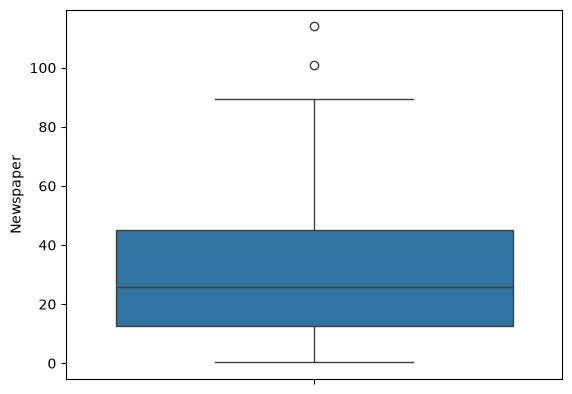

In [23]:
sns.boxplot(advertising["Newspaper"])

aykırı gözlem tesbiti

<Axes: ylabel='Newspaper'>

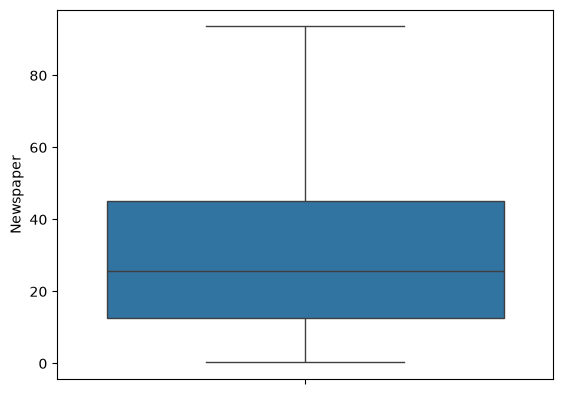

In [24]:
q1=advertising["Newspaper"].quantile(0.25)
q3=advertising["Newspaper"].quantile(0.75)
ıqr=q3-q1
üstsınır=q3+1.5*ıqr
advertising.loc[advertising["Newspaper"]>üstsınır,"Newspaper"]=üstsınır
sns.boxplot(advertising["Newspaper"])


aykırı gözlem değerlerini baskılıyoruz

In [29]:
y=advertising["Sales"]
x=advertising[["TV","Radio"]]
sabit=sm.add_constant(x)
model=sm.OLS(y,sabit).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Fri, 20 Nov 2026   Prob (F-statistic):          2.39e-100
Time:                        21:26:58   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.000       4.058       5.203
TV             0.0544      0.001     39.726      0.000       0.052       0.057
Radio          0.1072      0.008     13.522      0.000       0.092       0.123
==============================================================================
Omnibus:                       16.227   Durbin-Watson:                   2.252
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               27.973
Skew:                          -0.434   Prob(JB):                     8.43e-07
Kurtosis:                       4.613   Cond. No.                         425.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

mamkina öğrenmesi

In [26]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
lr=LinearRegression()
lr.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.05,0.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['TV','Radio']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.791
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


parçaladığımız data setini bir öğrenme sürecine soktuk.Bir model tahmin etti ve bu model üzerinden bir öğrenme yapısı geliştirdik.
y=b+b1x1+b2x2 yani satış=sabit+tv*x1+radio*x2 bir model oluşturduk.Bu model makinanın öğrendiği model(eğitim data setiyle bir model öğrendik).Bu modeli test etmek amacıyla bir data seti göndermemiz gerekiyor bu data seti ayırdığımız x (bağımsız) test setidir.Bağımsız değişkenin test datasını oluşturduğumuz modelin içerisine gönderip bir tahmin değeri yani y_tahmin değerini ortaya çıkarmamız gerekiyor sonrasında y_tahmin değerini elimizdeki ayırmış olduğumuz y_test değeri ile bir karşılaştırma yapmamız gerekiyor.

In [27]:
tahmin=lr.predict(x_test)
print(tahmin,y_test)



[16.95537518 20.36750946 23.67877906  9.23932462 21.8589777  12.49890184
 21.14158798  8.71453835 17.26489488 16.65891755  9.04850144  8.44326393
 17.92443396  8.17312478 12.61199966 14.8739442   8.09082502 17.9679393
 10.99191604 20.57101437 20.63604288 12.26621032 11.0239442  22.2361825
  9.51268565  7.91404079 20.86878181 13.8814929  10.76286373  8.05785124
 15.9504224  10.68007267 20.73382321 10.22491484 21.52687927 21.3167722
 12.2771962  22.6941923  12.69753173  6.45554633] 95     16.9
15     22.4
30     21.4
158     7.3
128    24.7
115    12.6
69     22.3
170     8.4
174    16.5
45     16.1
66     11.0
182     8.7
165    16.9
78      5.3
186    10.3
177    16.7
56      5.5
152    16.6
82     11.3
68     18.9
124    19.7
16     12.5
148    10.9
93     22.2
65     11.3
60      8.1
84     21.7
67     13.4
125    10.6
132     5.7
9      15.6
18     11.3
55     23.7
75      8.7
150    16.1
104    20.7
135    11.6
137    20.8
164    11.9
76      6.9
Name: Sales, dtype: float64


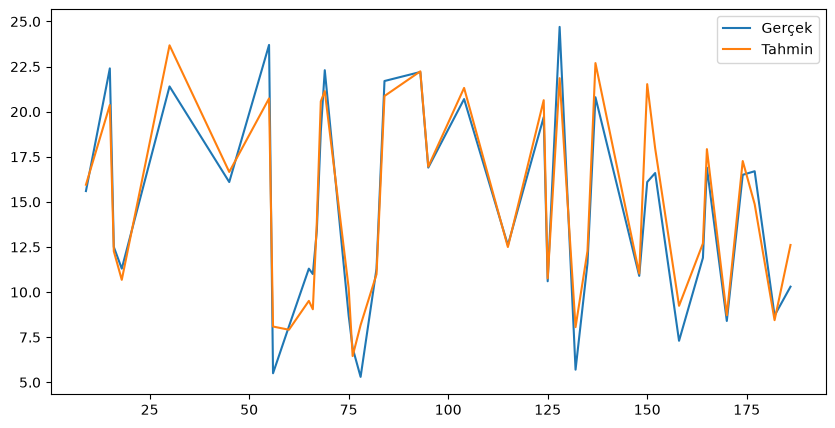

In [28]:
sonuç=pd.DataFrame({"Gerçek":y_test,"Tahmin":tahmin},index=y_test.index)
sonuç=sonuç.sort_index()
sonuç.plot(kind="line", figsize=(10, 5))
plt.show()
